In [29]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain.chat_models import init_chat_model
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableParallel, RunnableLambda, RunnableBranch, RunnablePassthrough
import os
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, ToolMessage
from langchain.tools import tool
from IPython.display import Image, display

load_dotenv()

llm_openai= init_chat_model(model=os.environ.get("LLM_MODEL"), temperature = 0.7)
# generation = input("Enter your generation (e.g., GenZ, Millennial, GenX): ")

In [30]:
from pydantic import BaseModel, Field
from typing import List, TypedDict

class llm_schema(BaseModel):
    tasks: List[str]=Field(description="A list of tasks to be performed by the worker.")

llm_with_schema=llm_openai.with_structured_output(llm_schema)

# llm_with_schema.invoke("Tell me the capital of France and also findout the latest news on AI.")

In [31]:
class graph_schema(TypedDict):
    tasks: List[str]
    query: str
    results: List[str]
    summary: str

### **Orchestrator Node**

In [32]:
def orchestrator_node(state:graph_schema)->graph_schema:
    query = state['query']

    # Create the prompt for the LLM
    prompt = ChatPromptTemplate.from_messages(
        [
            ("system", "You are an orchestrator that breaks down a user query into tasks for the worker."),
            ("user", f"User query: {query}. Please generate one prompt per task for the worker to complete. Return the tasks in a list format."),
        ]
    )

    # Create the chain
    chain = prompt | llm_with_schema

    response = chain.invoke({"query": query})

    state["tasks"] = response.tasks

    return state

### ***Worker Node***

In [33]:
# Execute Function

def execute(query:str) :

    response = llm_openai.invoke(f"Please execute this task {query}")
    return response.content

In [34]:
from concurrent.futures import ThreadPoolExecutor

def worker_node(state:graph_schema)->graph_schema:
    tasks = state['tasks']
    results = []

    with ThreadPoolExecutor(max_workers=len(tasks)) as executor:

        results_futures = executor.map(execute, tasks)
        for result in results_futures:
            results.append(result)

    state['results'] = results

    return state

### ***Collector Node***

In [38]:
def collector_node(state):
    
    results = state['results']
    
    prompt = ChatPromptTemplate.from_messages([
        ("system", "You are a collector that summarizes the results from the worker."),
        ("user", f"Here are the results from the worker: {results}. Please summarize these results in a concise manner."),
    ])
    chain = prompt | llm_openai
    summary = chain.invoke({"results": results})
    state['summary'] = summary.content

    return state

### ***Create Graph and Execute***

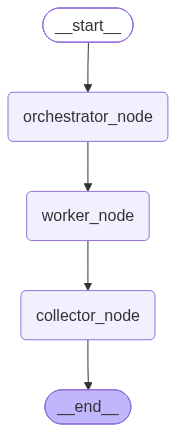

In [39]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

graph.add_node("orchestrator_node",orchestrator_node)
graph.add_node("worker_node",worker_node)
graph.add_node("collector_node",collector_node)

graph.add_edge(START, "orchestrator_node")
graph.add_edge("orchestrator_node", "worker_node")
graph.add_edge("worker_node", "collector_node")
graph.add_edge("collector_node", END)

complex_graph = graph.compile()

from IPython.display import Image, display

# You could see the errors with the below command
Image(complex_graph.get_graph().draw_mermaid_png())

In [41]:
complex_graph.invoke(
    {
        "query": """**1. Research and Summarization**
Explain the differences between LangChain, LangGraph, and CrewAI. Compare their architecture, state management, orchestration capabilities, and ideal use cases.
**2. Technical Code Generation**
Write a Python function to identify duplicate records in a dataset using PySpark. Include sample input, expected output, and an explanation of the logic.
**3. Data Analysis**
Analyze the following sales data:
- January: ₹120,000
- February: ₹145,000
- March: ₹132,000
- April: ₹178,000
- May: ₹195,000
Calculate total revenue, average monthly revenue, month-over-month growth, and the best-performing month.
**4. Problem-Solving and Debugging**
A Databricks PySpark pipeline that processes 10 million records is experiencing slow performance. Identify five potential bottlenecks and recommend optimizations for each.
**5. Multi-Step Planning**
Design a 30-day learning roadmap for mastering Agentic AI using LangGraph, covering foundational concepts, implementation, evaluation, and deployment.
**6. Comparative Evaluation**
Compare Snowflake, Databricks, and Microsoft Fabric for building an enterprise data platform. Evaluate scalability, cost considerations, governance, AI integration, and operational complexity.
**7. Architecture Design**
Design a production-grade RAG application using Azure AI Foundry, Azure AI Search, and an LLM. Explain the components, document ingestion, retrieval pipeline, security, evaluation, and monitoring.
**8. Risk Assessment**
Identify 10 potential failure scenarios in a multi-agent AI application. Categorize them by severity, likelihood, detection approach, and mitigation strategy.
**9. Complex Task Decomposition**
A multinational organization wants to build an AI-powered ESG Intelligence Platform.
Break the project into independent and dependent workstreams covering data ingestion, carbon accounting, regulatory compliance, predictive analytics, reporting, and quality assurance.
Recommend which workstreams can run concurrently and which require sequential execution.
**10. Final Synthesis and Decision-Making**
Using relevant outputs from Activities 1, 5, 7, 8, and 9, propose a production-ready architecture for an enterprise Agentic AI system.
Include:
- Recommended technology stack
- Orchestrator and worker responsibilities
- Parallel execution opportunities
- Dependency management
- State management and persistence
- Error handling and retry strategies
- Human-in-the-loop checkpoints
- Evaluation and observability
- Deployment considerations
""",
        "tasks": [],
        "results": [],
        "summary": "",
    }
)

ValueError: unexpected '{' in field name